# INM707-Deep-Learning Coursework: Bernardo Saab & James Ashdown



    ### Actions ###
    
      - 0: move down
      - 1: move up
      - 2: move left
      - 3: move right
      - 4: pickup hostage
      - 5: drop hostage
      - 6: open door
    
    ### States ###
    
    There are 800 maximum possible states 10x10 matrix x2 open door x2 pickup hostage x2 drop hostage
    There are walls inside the grid which receieve negative rewards if you turn into them. 
    The agent cannot move into a wall and therefore the state space is actually smaller in this regard (800-wall states)
    
    There are some special cells which the agent has to visit and perform specific actions these are:
    
    1) Pickup Hostage in Hostage Zone
    2) Pickup Key in Key Zone
    3) Open Door and Drop Hostage in Safe Zone 
    
    The Safe Zone is a terminal state and maximum reward occurs if the Agent has a key and hostage which is dropped in the safe zone
    
    There are two other scenarios the agent has to avoid:
    
    4) Entering a Mine near the Safe Zone - This is a terminal state
    5) Entering an Unsafe zone and dropping off the hostages - This is also a terminal state.    
    
    ### Epochs & Episodes ###
    
    The agent is allowed to traverse the state space ~ 200 times in a given episode
    We have allowed for a maximum of 100k episodes for the agent to learn an optimal solution
    Of course these are both parameters that are observeed and fine tuned during the training process
    Using a standard Q learning approach means that convergence can take quite some time. The agent is randomly 
    assigned to a new state after each episode and it has been observed the closer the agent is positioned near
    the key the faster the convergence of the algorithm
    
    ### Q LEarning ###
    
    The agent utilises Q learning and follows an episolon greedy approach with a decay function so that it starts off
    in an exploratory manner and the more it learns it takes a greedy approach for optimal reward. These parameters along with 
    learning rate are tested in a randomised grid search to ensure optimal performance. Average cumlative rewards by steps and 
    actions are plotted to find optimal plateaus on the minimum number of steps required to converge for each hyper parameter.
    
   

In [136]:
import matplotlib.pyplot as plt
import time 
import numpy as np
import pandas as pd
import random

# Main class

In [4]:
#These are the key actions you can apply at states
action_dict = {
    0: 'up',
    1: 'down',
    2: 'right',
    3: 'left',
    4: 'pickup',
    5: 'dropoff',
    6: 'open'
}

#Colours for environment
color2num = dict(
    gray=30,
    red=31,
    green=32,
    yellow=33,
    blue=34,
    magenta=35,
    cyan=36,
    white=37,
    crimson=38,
)

#Function to surround string with certain colour codes
def colorize(string, color, bold=False, highlight=False):
    attr = []
    num = color2num[color]
    if highlight:
        num += 10
    attr.append(str(num))
    if bold:
        attr.append("1")
    attrs = ";".join(attr)
    return f"\x1b[{attrs}m{string}\x1b[0m"

# A function that counts the number of true values when the cumulative sum of n probabilities
#In an array is greater than a randomly generated number used in the step function

def categorical_sample(prob_n, np_random):
    prob_n = np.asarray(prob_n)
    csprob_n = np.cumsum(prob_n)
    return (csprob_n > np_random.random()).argmax()

class MapWalkingEnv:

    def __init__(self, N, M):
        # Numpy array that holds the information about the environment
        self.territory = np.zeros((N, M), dtype = np.int8)
        self.height = N
        self.width = M
        self.size = N * M 
        self.average_size = round((N+M)/2,0)
        self.hostage = 1 # 1 hostage zones
        self.exit = 2 # 1 safe zone and 1 unsafe
        
        # Number of random objects
        self.number_keys = 1
        self.number_hostages = 1
        self.number_mines = 1
        self.exit_steps = None 

        # Define Walls
        wall_states = [(0,1),(1,5),(2,5),(3,0),(3,1),(3,3),(3,4),(3,6),(4,2),(4,4),(4,6),(4,7),(4,8),
                       (5,2),(5,4),(7,6),(7,7),(7,8),(7,9),(8,1),(8,2),(8,3),(8,4),(8,5),(9,7)]
        
        for i,j in wall_states:
            self.territory[i,j] = 1
        
        # Pick 1 random coordinates for the mine
        self.mine_coord = mine_coord = (0,9)
        self.territory[mine_coord[0], mine_coord[1]] = 2

        # Pick 2 random coordinatesto be safe zone and unsafe zone
        self.exit_coord = exit_coord = self.get_exit_cells(self.exit)
        self.exit_coord = exit_coord = ((0,8),(9,9))  #Debugging purposes (initial seed)
        self.territory[exit_coord[0][0], exit_coord[0][1]] = 5 # Safe
        self.territory[exit_coord[1][0], exit_coord[1][1]] = 6 # Unsafe
        
        # Pick 1 random coordinate for the key
        self.key_coord = key_coord = self.get_empty_cells(self.number_keys)
        self.key_coord = key_coord = (5,7) #Debugging purposes (initial seed)
        self.territory[key_coord[0],key_coord[1]] = 3
         
        # Pick 1 random coordinate for the hostage zone
        self.hostage_coord = hostage_coord = self.get_empty_cells(self.number_hostages)
        self.hostage_coord = hostage_coord = (9,8) #(9,6) #(2,4) #Debugging purposes (initial seed)
        self.territory[hostage_coord[0],hostage_coord[1]] = 4
        
        # initial position of the agent will be decided by resetting the environment.
        self.position_agent = None
        self.start_agent = None

        # run time
        self.time_elapsed = 0
        self.time_limit = 2*self.size #* 8

        # display help
        self.dict_map_display={ 0:'.', #0 : empty cell
                                1:'X', #1 : walls obstacle that are non-traversable
                                2:'M', #2 : mine field location
                                3:'K', #3 : key location
                                4:'H', #3 : hostage zone    
                                5:'S', #4 : safe zone
                                6:'U', #6 : unsafe zone
                                7:'A' #7 : agent location
                              }
       

        num_states = self.size * 8
        num_rows = N
        num_columns = M
        max_row = num_rows - 1
        max_col = num_columns - 1
        self.initial_state_distrib = np.zeros(num_states)
        num_actions = 7
        
        # Set available actions
        self.actions = [0,1,2,3,4,5,6]
        #self.actions = ['up','down','left','right','pickup','dropoff','open']
        
        self.P = {
            state: {action: [] for action in range(num_actions)}
            for state in range(num_states)
        }
        self.states_array = {
            state   : {}
            for state in range(num_states)
        }
        self.observations_array = {
            state   : {}
            for state in range(num_states)
        }
        
        # Create matrix of possible transitions, essentially like R matrix
        for row in range(num_rows): #7
            for col in range(num_columns): #7
                for key_idx in range(2): # +1 for key being with agent
                    for host_idx in range(2): # +1 for host being with agent
                        for exit_idx in range(2): # for tracking if door was opened or not
                            state = self.encode(row, col, key_idx, host_idx, exit_idx)
                            #if state == 69:
                            #    print(row, col, key_idx, host_idx, exit_idx)
                             
                            if  (self.territory[row, col] != 1) \
                                and self.territory[row, col] != 2 \
                                and (key_idx < 1 and host_idx < 1 and exit_idx < 1):
                                self.initial_state_distrib[state] += 1
                                self.states_array[state] = (row, col)
                            if  self.territory[row, col] != 1: 
                                self.observations_array[state] = (row, col)
                            
                            valid_actions = self.valid_actions(row, col)
                            
                            for action in valid_actions:
                                # defaults
                                new_row, new_col, new_key_idx, new_host_idx, new_exit_idx=row, col, key_idx, host_idx, exit_idx
                                reward = (
                                    0 #-0.1
                                )  # Default reward when there is no pickup/dropoff/open and agent moves to an open cell
                                
                                done = False
                                agent_loc = (row, col)
                                

                                if action == 0: #'up' 
                                    new_row = max(row - 1, 0)
                                elif action == 1: #'down' 
                                    new_row = min(row + 1, max_row)
                                elif action == 2: #'right' 
                                    new_col = min(col + 1, max_col)
                                elif action == 3: #'left':
                                    new_col = max(col - 1, 0)
                                elif action == 4: #'pickup' 
                                    if new_host_idx == 0 and new_key_idx == 1 and new_exit_idx == 1 and \
                                    (agent_loc == (hostage_coord[0],hostage_coord[1])):
                                        new_host_idx = 1
                                        reward = 20
                                    elif new_key_idx == 0 and (agent_loc == (key_coord[0],key_coord[1])):
                                        new_key_idx = 1
                                        reward = 20
                                    elif self.territory[new_row, new_col] != 2: # key not at location or agent did not open a door yet
                                        reward = -20
                                elif action == 5: #'dropoff' 
                                    if (agent_loc == (exit_coord[0][0],exit_coord[0][1]) and \
                                        new_key_idx == 1 and new_host_idx == 1):
                                        done = True
                                        reward = 100
                                    elif agent_loc == (exit_coord[1][0],exit_coord[1][1]) : #(agent_loc == (exit_coord[0][0],exit_coord[0][1]) and (new_key_idx == 0)) or \
                                        done = True
                                        reward = -100
                                    elif self.territory[new_row, new_col] != 2:  # dropoff at wrong location
                                        reward = -20
                                elif action == 6: #'open' 
                                    if (agent_loc == (exit_coord[0][0],exit_coord[0][1])) and (new_key_idx == 1 and new_exit_idx == 0):
                                        new_exit_idx = 1
                                        #reward = 20
                                    elif self.territory[new_row, new_col] != 2:  # open at wrong location
                                        reward = -20

                                if (new_host_idx == 1 and new_key_idx == 1) or \
                                    new_exit_idx == 1:
                                    new_exit_idx=1
                                else:
                                    new_exit_idx=0
                                    
                                # If the agent bumps into a wall, it doesn't move
                                if self.territory[new_row, new_col] == 1:
                                    new_row = row
                                    new_col = col
                                    reward = -10
                                
                                # If the agent bumps into a mine it reaches a terminal state:
                                if self.territory[new_row, new_col] == 2:
                                    new_row = row
                                    new_col = col
                                    done = True
                                    reward = -100 

                                if self.territory[row, col] != 1 and self.territory[row, col] != 2:
                                    new_state = self.encode(
                                        new_row, new_col, new_key_idx, new_host_idx, new_exit_idx
                                    )
                                    
                                    self.P[state][action].append((1.0, new_state, reward, done))
                       
        self.initial_state_distrib /= self.initial_state_distrib.sum()
        self.action_space = int(num_actions)
        self.state_space = int(num_states)
    
    def get_empty_cells(self, n_cells):
        empty_cells_coord = np.where( self.territory == 0 )
        selected_indices = np.random.choice( np.arange(len(empty_cells_coord[0])), n_cells )
        selected_coordinates = empty_cells_coord[0][selected_indices], empty_cells_coord[1][selected_indices]
        
        if n_cells == 1:
            return np.asarray(selected_coordinates).reshape(2,)
        
        return selected_coordinates
        
    def get_exit_cells(self, n_cells):
        y=np.arange(self.territory.shape[0] * self.territory.shape[1]).reshape(self.territory.shape[0], self.territory.shape[1])        
        border_coord_indices = list(np.unique(np.array(sorted(np.concatenate([y[0,:],y[-1,:],y[:,0], y[:,-1]]))).reshape(1,-1)))
        border_coord=np.zeros((2,len(border_coord_indices)),dtype = np.int8)
        border_coord[0] = [int(i) for i,ival in enumerate(y) for j,jval in enumerate(ival) if y[i,j] in border_coord_indices]
        border_coord[1] = [j for i,ival in enumerate(y) for j,jval in enumerate(ival) if y[i,j] in border_coord_indices]
        #print(border_coord_indices)
        #print(border_coord)
        selected_indices = np.random.choice( np.arange(len(border_coord[0])), n_cells )
        selected_coordinates = border_coord[0][selected_indices], border_coord[1][selected_indices]
        
        if n_cells == 1:
            return np.asarray(selected_coordinates).reshape(2,)
        
        return selected_coordinates
    
    
    # a key function for the q learning update rule
    def step(self, action):
        
        transitions = self.P[self.s][action]
        i = categorical_sample([t[0] for t in transitions], np.random)
        p, state, reward, done = transitions[i]
        self.s = state
        self.lastaction = action
        
        if done == False:
            self.position_agent = (self.observations_array[self.s][0],self.observations_array[self.s][1])

        # Update time elapsed
        self.time_elapsed+=1
        
        _, _, _, _, self.exit_steps = env.decode(env.s)

        if self.time_elapsed == self.time_limit:
            done = True
        
        return (int(state), reward, done, {"prob": p})
   

    def agent_on_map(self):
        #prints out current location of agent on the grid
        grid = np.zeros((self.N, self.M))
        grid[ self.current_location[0], self.current_location[1]] = 1
        return grid
    
    
    def encode(self, agent_row, agent_col, key_idx, host_idx, exit_idx):
        i = agent_row
        i *= 10
        i += agent_col
        i *= 2
        i += key_idx
        i *= 2
        i += host_idx
        i *= 2
        i += exit_idx
        return i

    def decode(self, i):
        out = []
        out.append(i % 2)
        i = i // 2
        out.append(i % 2)
        i = i // 2
        out.append(i % 2)
        i = i // 2
        out.append(i % 10)
        i = i // 10
        out.append(i)
        assert 0 <= i < 10
        return reversed(out)
    
    
    def display(self, mode='human'):
 
        envir_with_agent = self.territory.copy()
        envir_with_agent[self.position_agent[0], self.position_agent[1]] = 7
        #envir_with_agent[self.position_agent[0], self.position_agent[1]] = 7
        
        agent_row, agent_col, key_idx, host_idx, exit_idx = self.decode(self.s)

        full_repr = ""

        for r in range(self.height):
            
            line = ""
            
            for c in range(self.width):
                
                string_repr = self.dict_map_display[ envir_with_agent[r,c] ]
                line += "{0:2}".format(string_repr)

            full_repr += line + "\n"
        
        if key_idx == 1 and exit_idx == 0: # Agent found the key but did not open the door yet
            full_repr = full_repr.replace('A',colorize('A', "yellow", highlight=True))
        elif exit_idx == 1 and host_idx == 0: # Agent opened the door but did not find hostage
            full_repr = full_repr.replace('A',colorize('A', "blue", highlight=True))
        elif host_idx == 1: # Agent found the hostage
            full_repr = full_repr.replace('A',colorize('A', "green", highlight=True))

        print('Key (Yellow):',key_idx,'/ Door (Blue):',exit_idx,'/ Hostage (Green):',host_idx,'- Agent start',self.start_agent)
        print(full_repr)

        
    def calculate_observations(self):
        
        relative_coordinates = self.position_exit - self.position_agent
                
        surroundings = self.territory[ self.position_agent[0] -1: self.position_agent[0] +2,
                                     self.position_agent[1] -1: self.position_agent[1] +2]
        
        obs = {'relative_coordinates':relative_coordinates,
               'surroundings': surroundings}
        
        return obs
        
    def reset(self, return_info: bool = False):
        #This function resets the environment for the agent
        self.time_elapsed = 0
         
        invalid_position = True                                    


        while invalid_position == True:
            self.s = categorical_sample(self.initial_state_distrib, np.random)
            new_coord = self.states_array[self.s]
            #print(new_coord)
            if      ((new_coord[0],new_coord[1]) != (self.exit_coord[0][0],self.exit_coord[0][1])) \
                and ((new_coord[0],new_coord[1]) != (self.exit_coord[1][0],self.exit_coord[1][1])) \
                and ((new_coord[0],new_coord[1]) != (self.hostage_coord[0],self.hostage_coord[1])) \
                and ((new_coord[0],new_coord[1]) != (self.key_coord[0],self.key_coord[1])):
                invalid_position = False
                self.position_agent = (new_coord[0],new_coord[1])
        
        #self.position_agent = (6,9)
        self.start_agent = self.position_agent
        

        self.lastaction = None
        if not return_info:
            return int(self.s)
        else:
            return int(self.s), {"prob": 1}
        #return observations
        
        
    def valid_actions(self, row=None, col=None, cell=None):
        actions = [0, 1, 2, 3, 4, 5, 6]
        if (row == None and col == None):
            row = self.observations_array[self.s][0]
            col = self.observations_array[self.s][1]

        nrows, ncols = self.territory.shape
        if row == 0:
            actions.remove(0)
        elif row == nrows-1:
            actions.remove(1)

        if col == 0:
            actions.remove(3)
        elif col == ncols-1:
            actions.remove(2)
            
        return actions

# Q-Learning Training

In [154]:
%%time
"""Training the agent"""

"""Grid Search Parameters:""

Alpha Values: 0.9,0.1
Gamma Values: 0.8,0.5
Epsilon Values: 0.9,0.5

"""
from IPython.display import clear_output

# Variables
N = 10
M = 10
episodes = 100000

# Hyperparameters
alpha = 0.9 #0.1 or 0.9
gamma = 0.8 #0.5 or 0.8

# Exploration rate.
epsilon = 0.5 #0.5 ot 0.9

# Exploration decay rate.
DECAY_RATE = 0.99997 #0.9998          

# For plotting metrics
all_epochs = []
all_rewards = []


env = MapWalkingEnv(N,M)

Q = np.zeros([env.state_space, env.action_space])

for i in range(1, episodes):
    #reset the environment start of each episode being looped and randomly allocate agent
    state = env.reset()
    #reset the epoch steps to 0 and rewards to 0
    epochs, reward, cumreward = 0, 0, 0
    #reset terminal status to false
    done = False
    #reset number of epoch steps taken to terminal status to 0
    exit_num_steps = 0
    
    #while in new episode and not a terminal state 
    while not done:
        #define the valid actions that are allowed from the map walking environment
        valid_actions = env.valid_actions()
        # if there is an error with valid actions re run the step but there shouldnt be
        if not valid_actions: break
        # if a random number between 0 and 1 is less than our epsilon greedy value then Explore the space
        if random.uniform(0, 1) < epsilon: ################### HYPER PARAMETER ###################
            #Do this by taking a random choice of the list of valid actions at this step
            action = np.random.choice(valid_actions)
        else:
            #Otherwise set an action value array
            action_value = np.array([-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf])
            #For each action 0 to 6 in the Q matrix for a given state
            for action,value in enumerate(Q[state]):
                #If the action is a valid action for this step
                if action in valid_actions:
                    #Then calculate action_value for taking that action, this value in the Q matrix is a.k.a expected reward
                    action_value[action] = value
            #Once we know the expected rewards for all the valid actions we now take a greedy approach and 
            #Select the action which gives the maximum reward a.k.a Exploirting the learned values in the Q matrix
            action = np.random.choice(np.flatnonzero(action_value == action_value.max()))
        
        #Once we have selected an action we take it and observe the instant reward if there is one and the next state position
        next_state, reward, done, info = env.step(action) 
        
        ## Update the Q value ##
        
        #save existing value
        old_value = Q[state, action]
        #figure out what the maximum action value is from the next state, which could be better than what we arleady expected
        next_max = np.max(Q[next_state])
        # update the current state action pair using the q learning update rule which utilises the knowledge of the next state
        # which may have exploited prior knowledge or have gone in a random direction and learnt something new, which in turn
        # may have updated the current state expected reward if a higher reward was available going in the random direction
        #this in turn will allow better exploitation in the next episode as the algorithm learns the best states and actions to take
        new_value = old_value + alpha * ((reward + gamma * next_max) - old_value) ###### HYPER PARAMETERS ########
        Q[state, action] = new_value
        
        #calculate number of steps taken in the episode before exit
        if env.exit_steps == 1:
            exit_num_steps  = epochs  
            
        # go to the next state
        state = next_state
        
        #update the cumulative epochs and rewards
        epochs += 1
        cumreward += reward

    # if epsilon is > 0.15 then keep decaying otherwise just keep it at 0.15 to always maintain some exploration
    # this is because the state action space is quite large and want to ensure as many actions are taken as possible
    if epsilon > 0.15:
        epsilon *= DECAY_RATE                 # Decaying the exploration rate every episode.
    else:
        epsilon = 0.15
    
    all_epochs.append(epochs)
    all_rewards.append(cumreward)
    
    #outputs visual of the environment at every X episodes shwoing where the agent is
    if i % 100 == 0:
        clear_output(wait=True)
        print(f"Episode: {i}")
        env.display()
        print('Time Elapsed:',env.time_elapsed,'-','State:',env.s,'-','Action:',action_dict[action],'-','Reward:',reward,
        print('Steps to open door:',exit_num_steps, '-','Steps to complete:',exit_num_steps))
        
print("Training finished.\n")

Episode: 99900
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Green): 1 - Agent start (7, 3)
. X . . . . . . A M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . . . X H U 

Steps to open door: 91 - Steps to complete: 91
Time Elapsed: 92 - State: 71 - Action: dropoff - Reward: 100 None
Training finished.

Wall time: 11min 24s


# Training Results

In [143]:
#Base Scenario alpha=0.9,gamma=0.8,epsilon=0.9 WALLTIME = 12 Minutes
avgcumrewards=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
BaseOutput=pd.DataFrame(avgcumrewards)
BaseOutput.to_csv('Base_09_08_09.csv')

In [152]:
#Tune 1 alpha=0.1,gamma=0.8,epsilon=0.9 WALLTIME = 13 mins
avgcumrewardsTune1=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
Tune1Output=pd.DataFrame(avgcumrewardsTune1)
Tune1Output.to_csv('Tune1_01_08_09.csv')

In [155]:
#Tune 2 alpha=0.9,gamma=0.8,epsilon=0.5 WALLTIME = 11 mins
avgcumrewardsTune2=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
Tune2Output=pd.DataFrame(avgcumrewardsTune2)
Tune2Output.to_csv('Tune2_09_08_05.csv')

In [150]:
#Tune 3 alpha=0.9,gamma=0.5,epsilon=0.9 WALLTIME = 13 mins
avgcumrewardsTune3=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
Tune3Output=pd.DataFrame(avgcumrewardsTune3)
Tune3Output.to_csv('Tune3_09_05_09.csv')

In [ ]:
#Tune 4 alpha=0.9,gamma=0.5,epsilon=0.5
#avgcumrewardsTune4=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
#Tune4Output=pd.DataFrame(avgcumrewardsTune4)
#Tune4Output.to_csv('Tune4_09_05_05.csv')

In [160]:
AllSearchResults=pd.read_csv('AllSearchResults.csv')

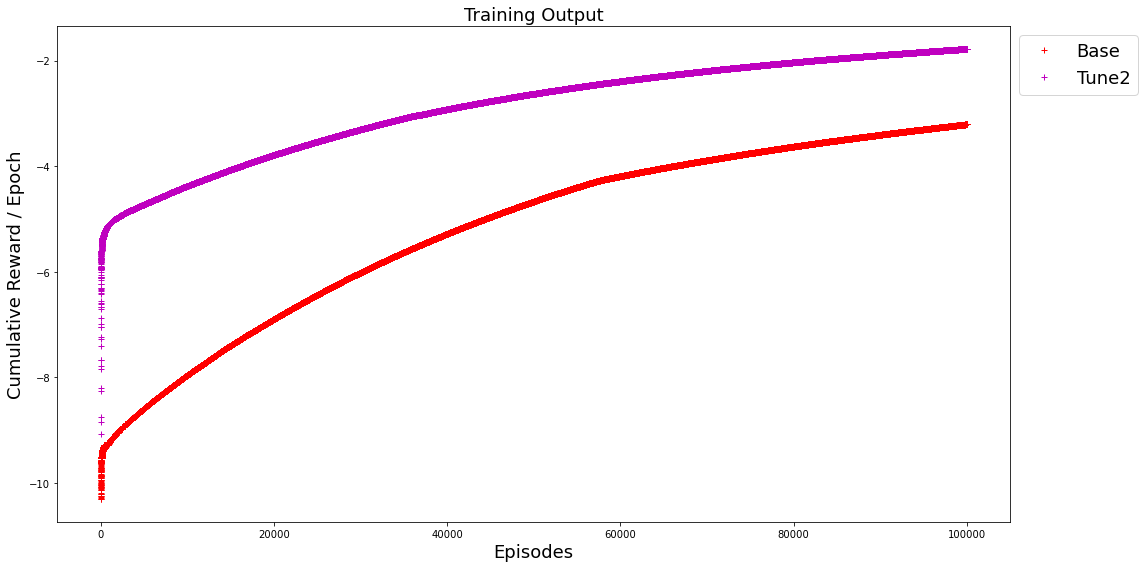

In [172]:
fig=plt.figure(figsize=(16,8),tight_layout=True)
ax1=fig.add_subplot()
ax1.plot(AllSearchResults['Base'],'+r',label ='Base')
ax1.plot(AllSearchResults['Tune2'],'+m',label ='Tune2')
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_ylabel("Cumulative Reward / Epoch",fontsize=18)
ax1.legend(loc=2,fontsize=18,bbox_to_anchor=(1, 1))
plt.title("Training Output",fontsize=18)
plt.show()

# Evaluation

In [46]:
#action = np.argmax(Q[state]) # Exploit learned values
action_value = np.array([-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf])
for action,value in enumerate(Q[state]):
    if action in valid_actions:
        action_value[action] = value
action = np.random.choice(np.flatnonzero(action_value == action_value.max())) # Exploit learned values
#action = np.argmax(action_value) # Exploit learned values

next_state, reward, done, info = env.step(action) 
print(next_state, reward, done, info)

232 0 False {'prob': 1.0}


In [47]:
agent_row, agent_col, key_idx, host_idx, exit_idx = env.decode(152)
print(agent_row, agent_col, key_idx, host_idx, exit_idx)

agent_row, agent_col, key_idx, host_idx, exit_idx = env.decode(156)
print(agent_row, agent_col, key_idx, host_idx, exit_idx)


1 9 0 0 0
1 9 1 0 0


In [48]:
"""Evaluate agent's performance after Q-learning"""

total_epochs, total_penalties = 0, 0
episodes = 2

for _ in range(episodes):
    state = env.reset()
    epochs, penalties, reward = 0, 0, 0
    
    done = False
    #env.display()
    while not done:
        valid_actions = env.valid_actions()
        if not valid_actions: break
        action_value = np.array([-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf])
        for action,value in enumerate(Q[state]):
            if action in valid_actions:
                action_value[action] = value
        action = np.random.choice(np.flatnonzero(action_value == action_value.max())) # Exploit learned values
        
        state, reward, done, info = env.step(action)

        if epochs < 50:
            print(env.time_elapsed,'-',env.s,'-',action_dict[action],'-',reward,'-',action)
            env.display()
        
        if reward < -1:
            penalties += 1

        
        epochs += 1

    total_penalties += penalties
    total_epochs += epochs

print(f"Results after {episodes} episodes:")
print(f"Average timesteps per episode: {total_epochs / episodes}")
print(f"Average penalties per episode: {total_penalties / episodes}")
print(f"Total penalties (Invalid pickups/dropoffs/open): {total_penalties}")

1 - 688 - left - 0 - 3
Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X A . . . 
. . . . . . . X H U 

2 - 768 - down - 0 - 1
Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . . A X H U 

3 - 760 - left - 0 - 3
Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . A . X H U 

4 - 752 - left - 0 - 3
Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green)

8 - 524 - down - 0 - 1
Key (Yellow): 1 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (5, 5)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . A . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . . . X H U 

9 - 604 - down - 0 - 1
Key (Yellow): 1 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (5, 5)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . A X X X X 
. X X X X X . . . . 
. . . . . . . X H U 

10 - 524 - up - 0 - 0
Key (Yellow): 1 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (5, 5)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . A . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . . . X H U 

11 - 604 - down - 0 - 1
Key (Yellow): 1 / Door (Blue): 0 / Hostage (Green)